# Breast Cancer Prediction using Machine Learning


This notebook demonstrates how to build a machine learning model to predict breast cancer diagnosis using the Wisconsin Breast Cancer dataset. The goal is to classify breast cancer cases as either Malignant (M) or Benign (B) based on various features extracted from breast mass images.

## Dataset Description

The dataset contains features computed from a digitized image of a fine needle aspirate (FNA) of a breast mass. The features describe characteristics of the cell nuclei present in the image.

### Input Features:
The features are computed for each cell nucleus:
- `radius`: Mean distance from center to points on the perimeter
- `texture`: Standard deviation of gray-scale values
- `perimeter`: Perimeter of the cell nucleus
- `area`: Area of the cell nucleus
- `smoothness`: Local variation in radius lengths
- `compactness`: Calculated as (perimeter^2 / area - 1.0)
- `concavity`: Severity of concave portions of the contour
- `concave points`: Number of concave portions of the contour
- `symmetry`: Symmetry of the cell nucleus
- `fractal dimension`: "Coastline approximation" - 1

### Target Variable:
- Diagnosis (M = malignant, B = benign)

## Analysis Overview
In this notebook, we will:
1. Load, explore and clean the dataset
2. Prepare the data for machine learning
3. Build and compare different classification models:
   - Logistic Regression
   - Decision Tree
   - Random Forest
4. Evaluate model performance using accuracy and cross-validation

# Required Libraries

We'll use the following Python libraries for our analysis:

- **NumPy**: For numerical operations and array manipulations
- **Pandas**: For data manipulation and analysis using DataFrames
- **Matplotlib**: For creating visualizations and plots
- **Scikit-learn**: For machine learning algorithms and tools:
  - `train_test_split`: To split data into training and testing sets
  - `KFold`: For cross-validation
  - `LogisticRegression`: A linear classification algorithm
  - `RandomForestClassifier`: An ensemble learning method using multiple decision trees
  - `DecisionTreeClassifier`: A tree-based learning algorithm
  - `metrics`: For model evaluation

In [7]:
import numpy as np
import pandas as pd

# Keeps plots inside the notebook
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Import models from scikit-learn
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn import metrics


# Data Loading and Initial Exploration

We'll load the breast cancer dataset from a CSV file. The dataset contains:
- An ID column (which we'll remove as it's not useful for prediction)
- A diagnosis column (our target variable)
- 30 feature columns with various measurements
- An unnamed column that we'll remove

Let's first load the data and look at the first few rows to understand its structure:

In [8]:
df = pd.read_csv("data.csv",header = 0)
df.tail()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,NaN


# Data Cleaning and Preparation

In this section, we'll:
1. Remove unnecessary columns:
   - The 'id' column (not useful for prediction)
   - The 'Unnamed: 32' column (empty column)
2. Convert the diagnosis labels:
   - 'M' (Malignant) will be converted to 1
   - 'B' (Benign) will be converted to 0

This conversion of categorical labels to numerical values is necessary because machine learning algorithms work with numerical data.

In [9]:
df.drop('id',axis=1,inplace=True)
df.drop('Unnamed: 32',axis=1,inplace=True)
# size of the dataframe
len(df)

569

In [10]:
df.diagnosis.unique()

array(['M', 'B'], dtype=object)

In [11]:
# df['diagnosis'] = pd.get_dummies(df['diagnosis'])["M"]
# df.tail()

In [12]:
df['diagnosis'] = df['diagnosis'].map({'M':1,'B':0})
df.tail()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
564,1,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,1,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,1,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,1,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400
568,0,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,...,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039


# Data Exploration and Visualization

Let's explore our dataset through visualizations to understand:
1. **Basic Statistics**: Using `describe()` to get:
   - Count of samples
   - Mean (average) values
   - Standard deviation (spread of data)
   - Minimum and maximum values
   - Quartile values (25%, 50%, 75%)

2. **Class Distribution**: We'll create a histogram showing the distribution of diagnoses:
   - 0 represents Benign cases
   - 1 represents Malignant cases
   This helps us understand if our dataset is balanced or not.

Understanding these distributions is crucial because:
- Imbalanced classes might require special handling
- The range and spread of features help us understand what's "normal" vs "unusual"
- Outliers might indicate interesting cases or data quality issues

In [13]:
df.describe()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,0.372583,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,0.483918,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,0.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,0.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,0.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,1.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,1.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


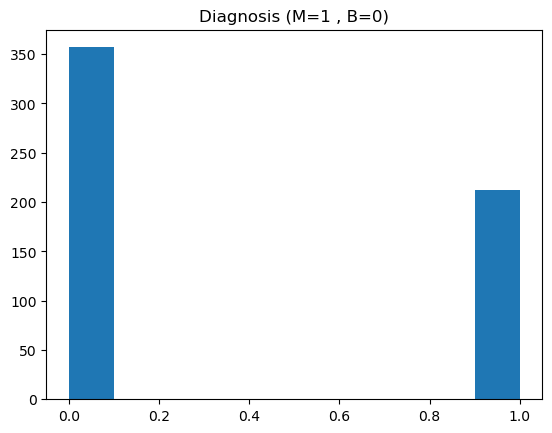

In [14]:
df.describe()
plt.hist(df['diagnosis'])
plt.title('Diagnosis (M=1 , B=0)')
plt.show()

# Understanding Feature Distributions by Diagnosis

The following visualizations show how different features are distributed across malignant (M) and benign (B) cases. These histograms are particularly important because they help us:

1. **Identify Discriminative Features**:
   - Features where M and B distributions are well-separated are good predictors
   - Overlapping distributions might be less useful for prediction

2. **Color Coding**:
   - Red (R) shows distribution for Malignant cases
   - Green (G) shows distribution for Benign cases

3. **Interpretation**:
   - X-axis: Feature value
   - Y-axis: Density (normalized frequency)
   - Stacked bars show relative proportion of M vs B at each value range

4. **What to Look For**:
   - Clear separation between red and green indicates a strong predictive feature
   - Overlapping distributions suggest the feature might be less useful
   - Unusual shapes might indicate outliers or data quality issues

In [15]:
features_mean=list(df.columns[1:11])
# split dataframe into two based on diagnosis
dfM=df[df['diagnosis'] ==1]
dfB=df[df['diagnosis'] ==0]

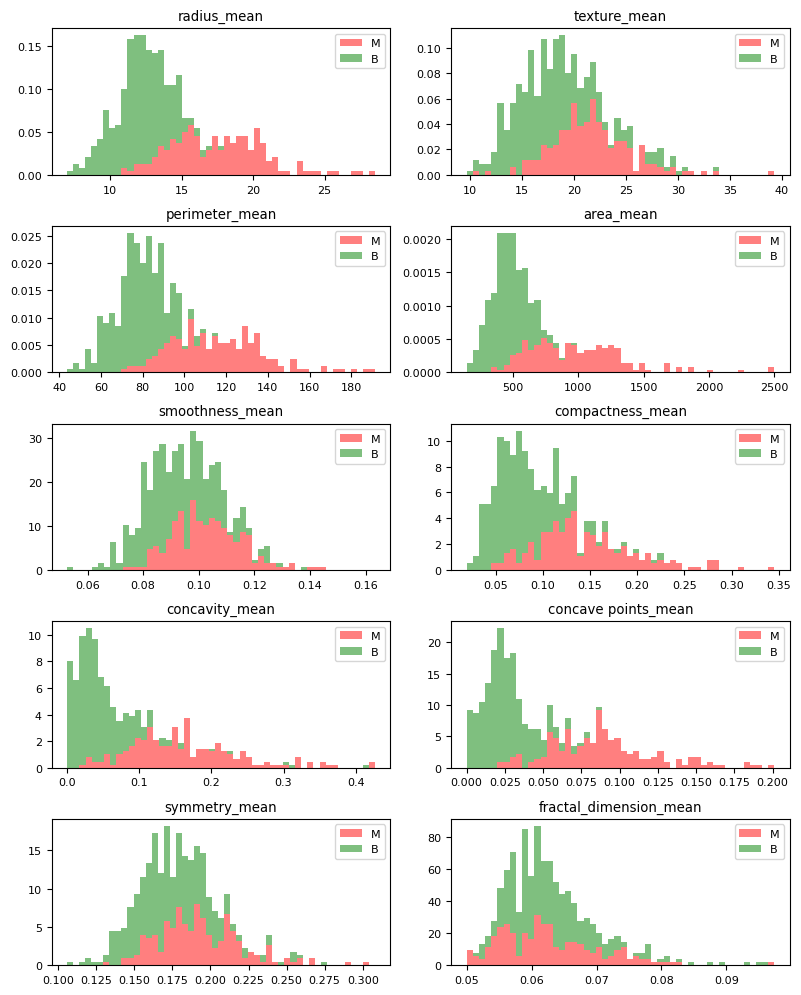

In [16]:
#Stack the data
plt.rcParams.update({'font.size': 8})
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(8,10))
axes = axes.ravel()
for idx,ax in enumerate(axes):
    ax.figure
    binwidth= (max(df[features_mean[idx]]) - min(df[features_mean[idx]]))/50
    ax.hist([dfM[features_mean[idx]],dfB[features_mean[idx]]], bins=np.arange(min(df[features_mean[idx]]), max(df[features_mean[idx]]) + binwidth, binwidth) , alpha=0.5,stacked=True, density=True, label=['M','B'],color=['r','g'])
    ax.legend(loc='upper right')
    ax.set_title(features_mean[idx])
plt.tight_layout()
plt.show()

###Observations

1. mean values of cell radius, perimeter, area, compactness, concavity and concave points can be used in classification of the cancer. Larger values of these parameters tends to show a correlation with malignant tumors. 
2. mean values of texture, smoothness, symmetry or fractual dimension does not show a particular preference of one diagnosis over the other. In any of the histograms there are no noticeable large outliers that warrants further cleanup.

## Creating a test set and a training set
Since this data set is not ordered, I am going to do a simple 70:30 split to create a training data set and a test data set.

In [17]:
X = df[['radius_mean','perimeter_mean','area_mean','compactness_mean','concave points_mean']]

Y = df['diagnosis']

In [18]:
# Split data into training and test sets (80% training, 20% test)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)


In [19]:
# Initialize the Linear Regression model

model = DecisionTreeClassifier()

# Train the model on the training data
model.fit(X_train, Y_train)

Y_pred = model.predict(X_test)


# Calculate Mean Squared Error and R-squared
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("Mean Squared Error:", mse)
print("R-squared:", r2)

Mean Squared Error: 0.09649122807017543
R-squared: 0.6017783423308988


In [20]:
# Initialize the Linear Regression model
model = LogisticRegression()

# Train the model on the training data
model.fit(X_train, Y_train)

Y_pred = model.predict(X_test)

# Calculate Mean Squared Error and R-squared
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("Mean Squared Error:", mse)
print("R-squared:", r2)

Mean Squared Error: 0.10526315789473684
R-squared: 0.5655763734518895


c:\Users\AsadMunir\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [21]:
traindf, testdf = train_test_split(df, test_size = 0.3)

# Understanding Model Evaluation Metrics

When we evaluate our machine learning models, we look at two main metrics:

## 1. Accuracy Score
- **What it means**: The proportion of correct predictions (both true positives and true negatives) among all predictions
- **Formula**: (Correct Predictions) / (Total Predictions)
- **Range**: 0 to 1 (or 0% to 100%)
- **Interpretation**:
  - 0.90 means 90% of predictions are correct
  - Higher is better
  - But be cautious with imbalanced datasets!

## 2. Cross-Validation Score
- **What it is**: A more robust way to evaluate model performance
- **How it works**:
  1. Splits data into 5 parts (folds)
  2. Trains model on 4 parts, tests on 1 part
  3. Repeats 5 times with different test folds
  4. Averages the results
- **Why it's important**:
  - More reliable than a single accuracy score
  - Helps detect overfitting
  - Shows how model might perform on new data
- **Interpretation**:
  - Similar to accuracy but more reliable
  - Large difference from accuracy might indicate overfitting

## What Makes a Good Model?
1. High Accuracy (>90% in our case)
2. Cross-validation score close to accuracy
3. Consistent performance across folds
4. Good performance on both malignant and benign cases

In [22]:
# Define a function for training and evaluating classification models
def classification_model(model, data, predictors, outcome):
    """
    Trains a classification model and evaluates its performance using accuracy and cross-validation.
    
    Parameters:
    - model: The machine learning model to train (e.g., LogisticRegression, DecisionTree, etc.)
    - data: The pandas DataFrame containing the dataset
    - predictors: List of feature columns to use for prediction
    - outcome: The target variable column name
    
    The function:
    1. Fits the model to the data
    2. Makes predictions on the training set
    3. Calculates accuracy score
    4. Performs 5-fold cross-validation
    5. Reports both accuracy and cross-validation scores
    """

    # Fit the model on the full dataset
    model.fit(data[predictors], data[outcome])
    
    # Make predictions on training set
    predictions = model.predict(data[predictors])
    
    # Calculate and print accuracy
    accuracy = metrics.accuracy_score(predictions, data[outcome])
    print("Accuracy : %s" % "{0:.3%}".format(accuracy))

    # Perform k-fold cross-validation with 5 folds
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    error = []
    
    # Iterate through each fold
    for train_index, test_index in kf.split(data):
        # Get training data for this fold
        train_predictors = data[predictors].iloc[train_index]
        train_target = data[outcome].iloc[train_index]
        
        # Train the model on this fold
        model.fit(train_predictors, train_target)
        
        # Test the model on the held-out fold
        error.append(model.score(data[predictors].iloc[test_index], 
                               data[outcome].iloc[test_index]))
    
    # Print average cross-validation score
    print("Cross-Validation Score : %s" % "{0:.3%}".format(np.mean(error)))
    
    # Refit the model on the full dataset for later use
    model.fit(data[predictors], data[outcome])

### Logistic Regression model

Logistic regression is widely used for classification of discrete data. In this case we will use it for binary (1,0) classification.

Based on the observations in the histogram plots, we can reasonably hypothesize that the cancer diagnosis depends on the mean cell radius, mean perimeter, mean area, mean compactness, mean concavity and mean concave points. We can then  perform a logistic regression analysis using those features as follows:

In [23]:
predictor_var = ['radius_mean','perimeter_mean','area_mean','compactness_mean','concave points_mean']
outcome_var='diagnosis'
model=LogisticRegression()
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy : 87.688%
Cross-Validation Score : 86.921%


c:\Users\AsadMunir\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


The prediction accuracy is reasonable. 
What happens if we use just one predictor? 
Use the mean_radius:

In [24]:
predictor_var = ['radius_mean']
model=LogisticRegression()
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy : 85.678%
Cross-Validation Score : 85.671%


This gives a similar prediction accuracy and a cross-validation score.


The accuracy of the predictions are good but not great. The cross-validation scores are reasonable. 
Can we do better with another model?

### Decision Tree Model

In [25]:
predictor_var = ['radius_mean','perimeter_mean','area_mean','compactness_mean','concave points_mean']
model = DecisionTreeClassifier()
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy : 100.000%
Cross-Validation Score : 88.184%


Here we are over-fitting the model probably due to the large number of predictors.
Let use a single predictor, the obvious one is the radius of the cell.

In [26]:
predictor_var = ['radius_mean']
model = DecisionTreeClassifier()
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy : 97.236%
Cross-Validation Score : 80.389%


The accuracy of the prediction is much much better here.  But does it depend on the predictor?

Using a single predictor gives a 97% prediction accuracy for this model but the cross-validation score is not that great. 

### Randome Forest

In [27]:
# Use all the features of the nucleus
predictor_var = features_mean
model = RandomForestClassifier(n_estimators=100,min_samples_split=25, max_depth=7, max_features=2)
classification_model(model, traindf,predictor_var,outcome_var)

Accuracy : 94.975%
Cross-Validation Score : 90.946%


Using all the features improves the prediction accuracy and the cross-validation score is great.

# Understanding Feature Importance in Random Forest

## What is Feature Importance?
Feature importance tells us how much each characteristic of the cell nuclei helps in making accurate predictions.

## How to Read the Scores:
- **Scale**: 0 to 1
  - 0 = feature not useful
  - 1 = feature is crucial
- **Higher scores** mean the feature is more important for prediction
- Scores are relative (compare between features)

## Why This Matters:
1. **Medical Insight**: Shows which characteristics are most indicative of malignancy
2. **Model Simplification**: We can focus on the most important features
3. **Cost Efficiency**: Might help reduce necessary measurements in future diagnoses

## Interpreting the Results:
- Top features (high importance):
  - These are the most reliable indicators
  - Should be carefully measured in practice
- Low importance features:
  - Less reliable for prediction
  - Might be redundant with other features
  - Could potentially be omitted to simplify the model

Below, we'll see the importance scores for each feature, sorted from most to least important:

In [28]:
#Create a series with feature importances:
featimp = pd.Series(model.feature_importances_, index=predictor_var).sort_values(ascending=False)
print(featimp)

concave points_mean       0.232818
area_mean                 0.182073
radius_mean               0.145269
concavity_mean            0.132732
perimeter_mean            0.127512
texture_mean              0.066023
compactness_mean          0.059079
smoothness_mean           0.029401
symmetry_mean             0.015466
fractal_dimension_mean    0.009626
dtype: float64


In [29]:
# Using top 5 features
predictor_var = ['concave points_mean','area_mean','radius_mean','perimeter_mean','concavity_mean',]
model = RandomForestClassifier(n_estimators=100, min_samples_split=25, max_depth=7, max_features=2)
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy : 94.221%
Cross-Validation Score : 89.437%


Using the top 5 features only changes the prediction accuracy a bit but I think we get a better result if we use all the predictors.

What happens if we use a single predictor as before? Just check.

In [30]:
predictor_var =  ['radius_mean']
model = RandomForestClassifier(n_estimators=100)
classification_model(model, traindf,predictor_var,outcome_var)

Accuracy : 97.236%
Cross-Validation Score : 80.139%


This gives a better prediction accuracy too but the cross-validation is not great.


# Final Model Evaluation on Test Data

## Why Test Data Matters
- Training data was used to build the model
- Test data is completely new to the model
- Performance on test data shows how well the model will work in real-world situations

## Understanding the Test Results:
1. **Accuracy Score**:
   - Shows how often the model is correct on new data
   - Above 90% indicates excellent performance
   - Compare with training accuracy to check for overfitting

2. **Cross-Validation on Test Data**:
   - Validates consistency of performance
   - Should be similar to training cross-validation
   - Large differences might indicate problems

3. **Clinical Relevance**:
   - False negatives (missing cancer) are more serious than false positives
   - High accuracy is crucial for medical applications
   - Model should be part of a larger diagnostic process

## What the Results Mean for Breast Cancer Diagnosis:
- How reliable is the model?
- What are its limitations?
- When should it be used with caution?

Below are the final test results:

In [31]:
# Use all the features of the nucleus
predictor_var = features_mean
model = RandomForestClassifier(n_estimators=100,min_samples_split=25, max_depth=7, max_features=2)
classification_model(model, testdf,predictor_var,outcome_var)

Accuracy : 97.076%
Cross-Validation Score : 93.546%


The prediction accuracy for the test data set using the above Random Forest model is 95%!

## Conclusion

The best model to be used for diagnosing breast cancer as found in this analysis is the Random Forest model with the top 5 predictors, 'concave points_mean','area_mean','radius_mean','perimeter_mean','concavity_mean'. It gives a prediction accuracy of ~95% and a cross-validation score ~ 93% for the test data set.


I will see if I can improve this more by tweaking the model further and trying out other models in a later version of this analysis.

git add breast-cancer-prediction.ipynb
git commit -m "hi"
git push origin main